# Phân loại chuỗi theo ADI–CV² và tốc độ bán (speed)
Thống kê chỉ tính trên train (ngưỡng speed = tam phân vị doanh số trung bình của train).

In [1]:
import sys
from pathlib import Path
ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))
import pandas as pd
from src import eda
from src.features import compute_series_features, plot_adi_cv2
data = pd.read_parquet(ROOT / 'data/processed/ca1_foods3.parquet')
features = compute_series_features(data)
saved = pd.read_csv(ROOT / 'results/series_classes.csv')
assert (saved.sort_values('id').reset_index(drop=True)[['demand_type','speed']].equals(features.sort_values('id').reset_index(drop=True)[['demand_type','speed']])), 'series_classes.csv lệch so với tính lại'
print('series_classes.csv khớp tính lại, số chuỗi =', len(features))
print(features['demand_type'].value_counts().sort_index())

series_classes.csv khớp tính lại, số chuỗi = 823
demand_type
erratic          45
intermittent    419
lumpy           239
smooth          120
Name: count, dtype: int64


In [2]:
tab = eda.demand_speed_table(features)
tab.to_csv(ROOT / 'results/tables/demand_speed_counts.csv')
tab

speed,fast,medium,slow,total
demand_type,,,,
erratic,45,0,0,45
intermittent,74,203,142,419
lumpy,89,116,34,239
smooth,118,2,0,120
total,326,321,176,823


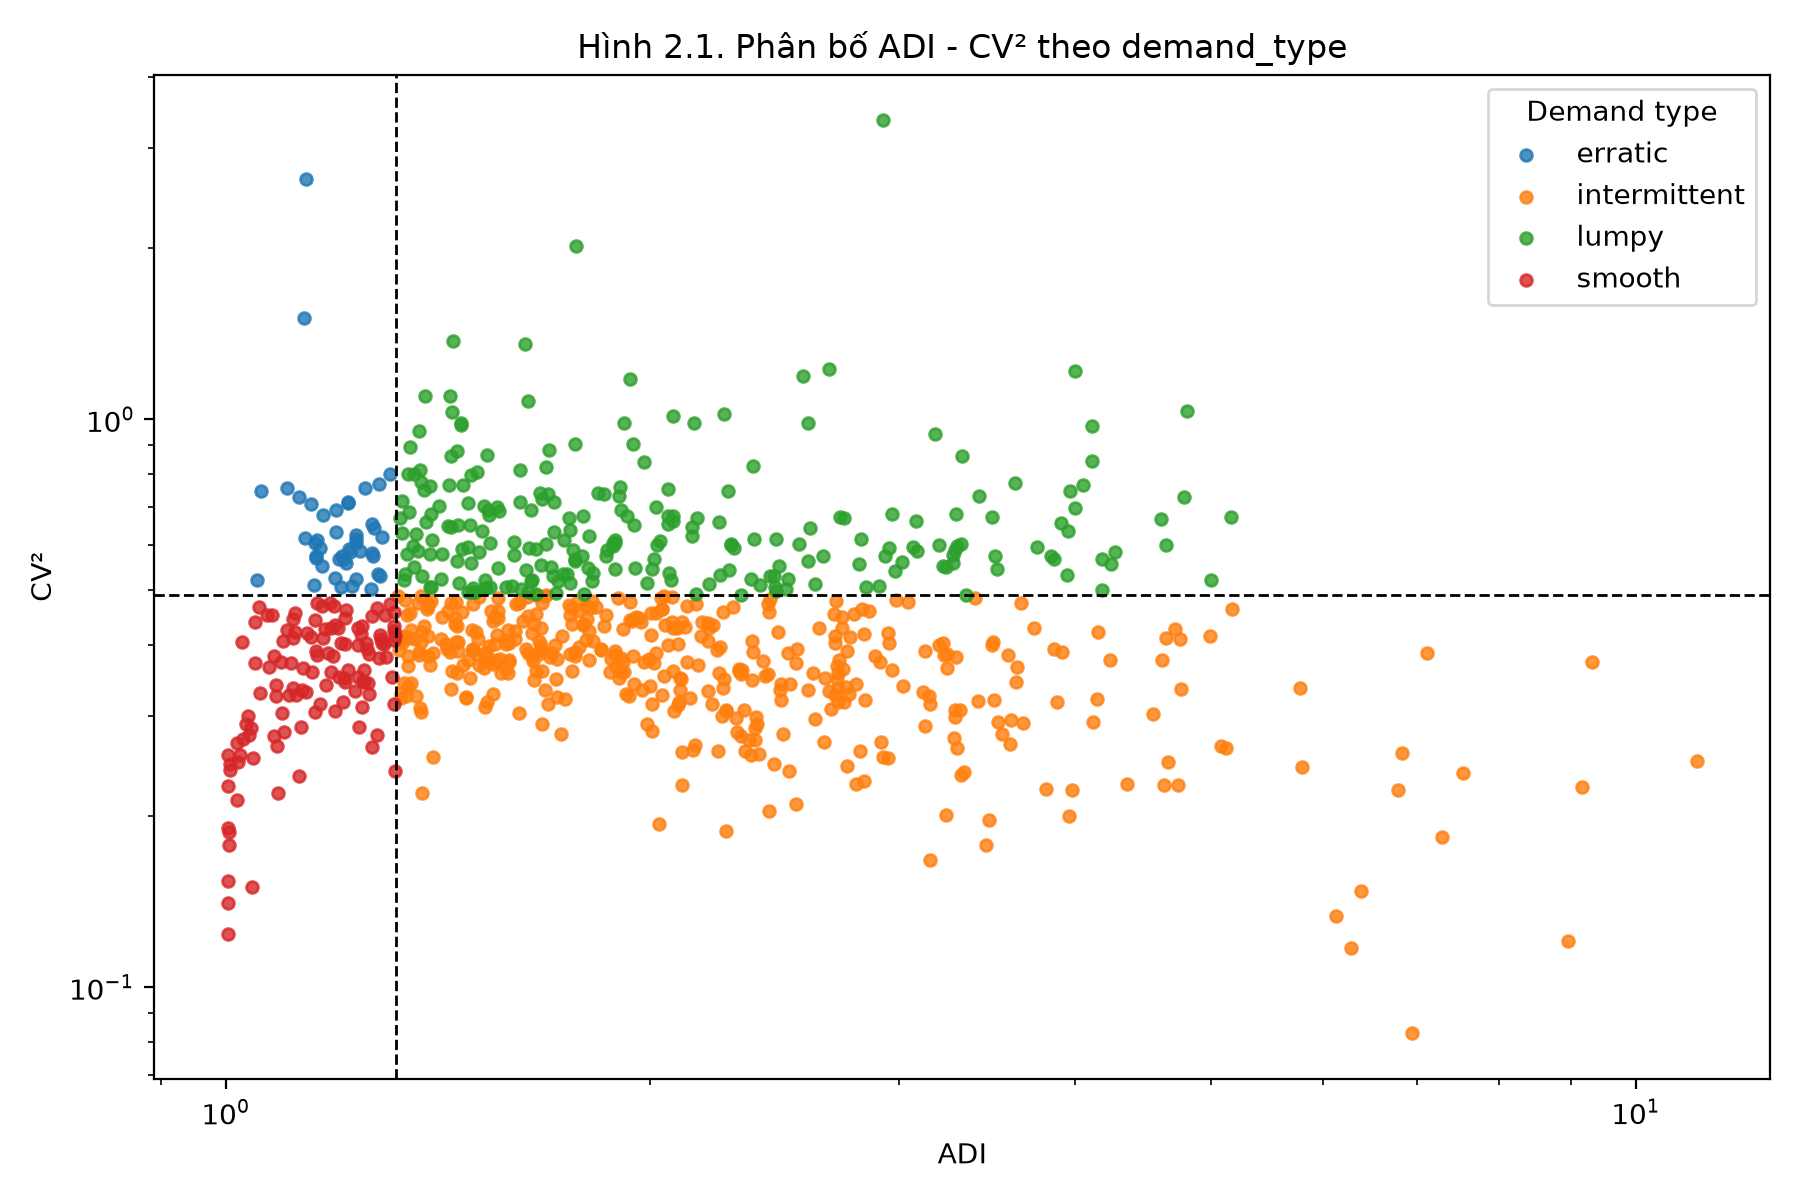

In [3]:
plot_adi_cv2(features, ROOT / 'results/figures/adi_cv2_scatter.png')
from IPython.display import Image
Image(str(ROOT / 'results/figures/adi_cv2_scatter.png'), width=700)

In [4]:
print(features.groupby('speed')['avg_demand'].describe().round(4))
print(features.groupby('demand_type')[['adi','cv2','zero_rate']].median().round(4))

        count    mean     std     min     25%     50%     75%      max
speed                                                                 
fast    326.0  5.8374  6.7336  1.8088  2.4621  3.6981  5.9064  66.7268
medium  321.0  1.1916  0.3121  0.6897  0.9283  1.1735  1.4371   1.7868
slow    176.0  0.4920  0.1442  0.1276  0.3991  0.5197  0.6079   0.6785
                 adi     cv2  zero_rate
demand_type                            
erratic       1.2122  0.6037     0.1751
intermittent  2.0382  0.3774     0.5094
lumpy         1.8620  0.6048     0.4629
smooth        1.1614  0.3612     0.1390
